# Fase 3 · Preparación y modelado de datos
**Proyecto de Business Intelligence · COVID-19 · Equipo 7**
Análisis de Datos · Ingeniería de Sistemas · ITM · 2026-2

**Dataset:** Our World in Data (OWID), COVID-19: `owid-covid-data.csv`.

- **H1:** el PIB per cápita influye en la mortalidad reportada por COVID-19.
- **H2:** vacunarse más rápido redujo las muertes.

In [2]:
# Importación de libre
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


#pd.set_option('display.max_columns', 40)
#pd.set_option("display.width", 160)


url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
salida = Path("datos_procesados")
salida.mkdir(exist_ok=True)

## 1. Carga y exploración inicial

In [3]:
raw = pd.read_csv(url, low_memory=False)  #Obliga a pandas a leer el archivo completo en memoria, evitando advertencias de tipo de datos mixtos.
print("Filas x Columnas:", raw.shape)
print("Ubicacion:", raw["location"].unique)
print("Periodo:", raw["date"].min(), "->", raw["date"].max())

Filas x Columnas: (429435, 67)
Ubicacion: <bound method Series.unique of 0         Afghanistan
1         Afghanistan
2         Afghanistan
3         Afghanistan
4         Afghanistan
             ...     
429430       Zimbabwe
429431       Zimbabwe
429432       Zimbabwe
429433       Zimbabwe
429434       Zimbabwe
Name: location, Length: 429435, dtype: object>
Periodo: 2020-01-01 -> 2024-08-14


In [ ]:
# Agrupación de columnas por tipo de dato.
raw.columns.to_list()

['iso_code',
 'continent',
 'location',
 'date',
 'total_cases',
 'new_cases',
 'new_cases_smoothed',
 'total_deaths',
 'new_deaths',
 'new_deaths_smoothed',
 'total_cases_per_million',
 'new_cases_per_million',
 'new_cases_smoothed_per_million',
 'total_deaths_per_million',
 'new_deaths_per_million',
 'new_deaths_smoothed_per_million',
 'reproduction_rate',
 'icu_patients',
 'icu_patients_per_million',
 'hosp_patients',
 'hosp_patients_per_million',
 'weekly_icu_admissions',
 'weekly_icu_admissions_per_million',
 'weekly_hosp_admissions',
 'weekly_hosp_admissions_per_million',
 'total_tests',
 'new_tests',
 'total_tests_per_thousand',
 'new_tests_per_thousand',
 'new_tests_smoothed',
 'new_tests_smoothed_per_thousand',
 'positive_rate',
 'tests_per_case',
 'tests_units',
 'total_vaccinations',
 'people_vaccinated',
 'people_fully_vaccinated',
 'total_boosters',
 'new_vaccinations',
 'new_vaccinations_smoothed',
 'total_vaccinations_per_hundred',
 'people_vaccinated_per_hundred',
 'peo

In [8]:
# Impresión de las primeras 3 filas del DataFrame para inspección visual.
raw.head(10)

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
5,AFG,Asia,Afghanistan,2020-01-10,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
6,AFG,Asia,Afghanistan,2020-01-11,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
7,AFG,Asia,Afghanistan,2020-01-12,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
8,AFG,Asia,Afghanistan,2020-01-13,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
9,AFG,Asia,Afghanistan,2020-01-14,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429435 entries, 0 to 429434
Data columns (total 67 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   iso_code                                    429435 non-null  object 
 1   continent                                   402910 non-null  object 
 2   location                                    429435 non-null  object 
 3   date                                        429435 non-null  object 
 4   total_cases                                 411804 non-null  float64
 5   new_cases                                   410159 non-null  float64
 6   new_cases_smoothed                          408929 non-null  float64
 7   total_deaths                                411804 non-null  float64
 8   new_deaths                                  410608 non-null  float64
 9   new_deaths_smoothed                         409378 non-null  float64
 

In [6]:
raw.describe()

,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths_per_million,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
count,4.118040e+05,4.101590e+05,4.089290e+05,4.118040e+05,410608.000000,409378.000000,411804.000000,410159.000000,408929.000000,411804.000000,...,243817.000000,161741.000000,290689.000000,390299.000000,319127.000000,4.294350e+05,1.341100e+04,13411.000000,13411.000000,13411.000000
mean,7.365292e+06,8.017360e+03,8.041026e+03,8.125957e+04,71.852139,72.060828,112096.199420,122.357073,122.713852,835.514337,...,33.097758,50.649390,3.106895,73.702098,0.722178,1.520336e+08,5.604765e+04,9.766431,10.925353,1772.666404
std,4.477582e+07,2.296649e+05,8.661611e+04,4.411901e+05,1368.322990,513.636565,162240.412405,1508.778585,559.701663,1134.932641,...,13.853952,31.905236,2.549168,7.387914,0.149237,6.975408e+08,1.568691e+05,12.040658,24.560706,1991.892770
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,7.700000,1.190000,0.100000,53.280000,0.390000,4.700000e+01,-3.772610e+04,-44.230000,-95.920000,-2936.450000
25%,6.280750e+03,0.000000e+00,0.000000e+00,4.300000e+01,0.000000,0.000000,1916.100000,0.000000,0.000000,24.570000,...,22.600000,20.860000,1.300000,69.500000,0.600000,5.237980e+05,1.765000e+02,2.060000,-1.500000,116.875000
50%,6.365300e+04,0.000000e+00,1.200000e+01,7.990000e+02,0.000000,0.000000,29145.480000,0.000000,2.790000,295.090000,...,33.100000,49.540000,2.500000,75.050000,0.740000,6.336393e+06,6.815200e+03,8.130000,5.660000,1270.800000
75%,7.582720e+05,0.000000e+00,3.132900e+02,9.574000e+03,0.000000,3.140000,156770.190000,0.000000,56.250000,1283.820000,...,41.500000,82.500000,4.210000,79.460000,0.830000,3.296952e+07,3.912804e+04,15.160000,15.575000,2883.025000
max,7.758668e+08,4.423623e+07,6.319461e+06,7.057132e+06,103719.000000,14817.000000,763598.600000,241758.230000,34536.890000,6601.110000,...,78.100000,100.000000,13.800000,86.750000,0.960000,7.975105e+09,1.349776e+06,78.080000,378.220000,10293.520000


## 2. Limpieza

### Filas que no son países
OWID mezcla países con **agregados**: World, continentes, grupos de ingreso y la Unión Europea. Si se dejan, los totales se cuentan dos o tres veces.

In [9]:
especiales = (raw[raw["iso_code"].str.startswith("OWID_")]
              .groupby(["iso_code", "location"], dropna=False)
              .agg(continente=("continent", "first"),
                   filas=("date", "size"),
                   filas_con_muertes=("total_deaths", "count"),
                   filas_con_vacunas=("people_vaccinated", "count")))
especiales

,,continente,filas,filas_con_muertes,filas_con_vacunas
iso_code,location,,,,
OWID_AFR,Africa,None,1674,1674,1087
OWID_ASI,Asia,None,1684,1674,1339
OWID_CYN,Northern Cyprus,Asia,691,0,24
OWID_ENG,England,Europe,1359,0,826
OWID_EUN,European Union (27),None,3024,1674,1350
OWID_EUR,Europe,None,1684,1674,1352
OWID_HIC,High-income countries,None,3026,1674,1352
OWID_KOS,Kosovo,Europe,1674,1674,446
OWID_LIC,Low-income countries,None,2724,1674,1050


In [13]:
SUBNACIONALES = ["OWID_ENG", "OWID_SCT", "OWID_WLS", "OWID_NIR", "OWID_CYN"]

df = raw[raw["continent"].notna() & ~raw["iso_code"].isin(SUBNACIONALES)].copy()

print("Ubicaciones antes:", raw["location"].nunique(), "/ países después:", df["location"].nunique())
print("Filas antes:", len(raw), "/ filas después:", len(df))

Ubicaciones antes: 255 / países después: 238
Filas antes: 429435 / filas después: 396985


In [18]:
#Conversión de la columna "date" a tipo datetime para facilitar análisis temporales.

df["date"] = pd.to_datetime(df["date"])
df[["iso_code", "location", "date", "total_deaths", "people_vaccinated"]].dtypes

iso_code                     object
location                     object
date                 datetime64[ns]
total_deaths                float64
people_vaccinated           float64
dtype: object

In [ ]:
df_duplicate = df[df.duplicated(["iso_code", "date"], keep=False)]
print("Filas con país-fecha repetido:", len(df_duplicate))
print("Filas totalmente idénticas (todas las columnas iguales):", int(df.duplicated().sum()))
df_duplicate.groupby("location").agg(filas=("date", "size"), desde=("date", "min"), hasta=("date", "max"))

Filas con país-fecha repetido: 0
Filas totalmente idénticas (todas las columnas iguales): 0


,filas,desde,hasta
location,,,


In [26]:
rows_before = len(df)
#print("Filas antes:", rows_before)

df = (df.sort_values(["iso_code", "date"])
        .groupby(["iso_code", "date"], as_index=False)
        .first())
print("Filas antes:", rows_before, "-> después:", len(df), "| duplicados restantes:", int(df.duplicated(["iso_code", "date"]).sum()))

Filas antes: 395577 -> después: 395577 | duplicados restantes: 0


In [40]:
ultima_fecha_con_datos = df.loc[df["new_deaths"] > 0, "date"].max()
print("Última fecha con muertes reportadas:", ultima_fecha_con_datos.date())
print("Filas posteriores (vacías) que se eliminan:", int((df["date"] > ultima_fecha_con_datos).sum()))
df = df[df["date"] <= ultima_fecha_con_datos]

Última fecha con muertes reportadas: 2024-08-04
Filas posteriores (vacías) que se eliminan: 60


In [ ]:
"""dias = df.loc[df["new_deaths"] > 0, "date"].dt.day_name().value_counts()
print("Días de la semana con muertes nuevas > 0:")
print(dias)
print("\nEjemplo, Colombia en junio de 2021 (los 6 días entre domingos tienen 0):")
df.loc[(df["location"] == "Colombia") & df["date"].between("2021-06-06", "2021-06-14"),
       ["date", "new_cases", "new_deaths", "total_deaths"]"""

## 3. Selección de variables

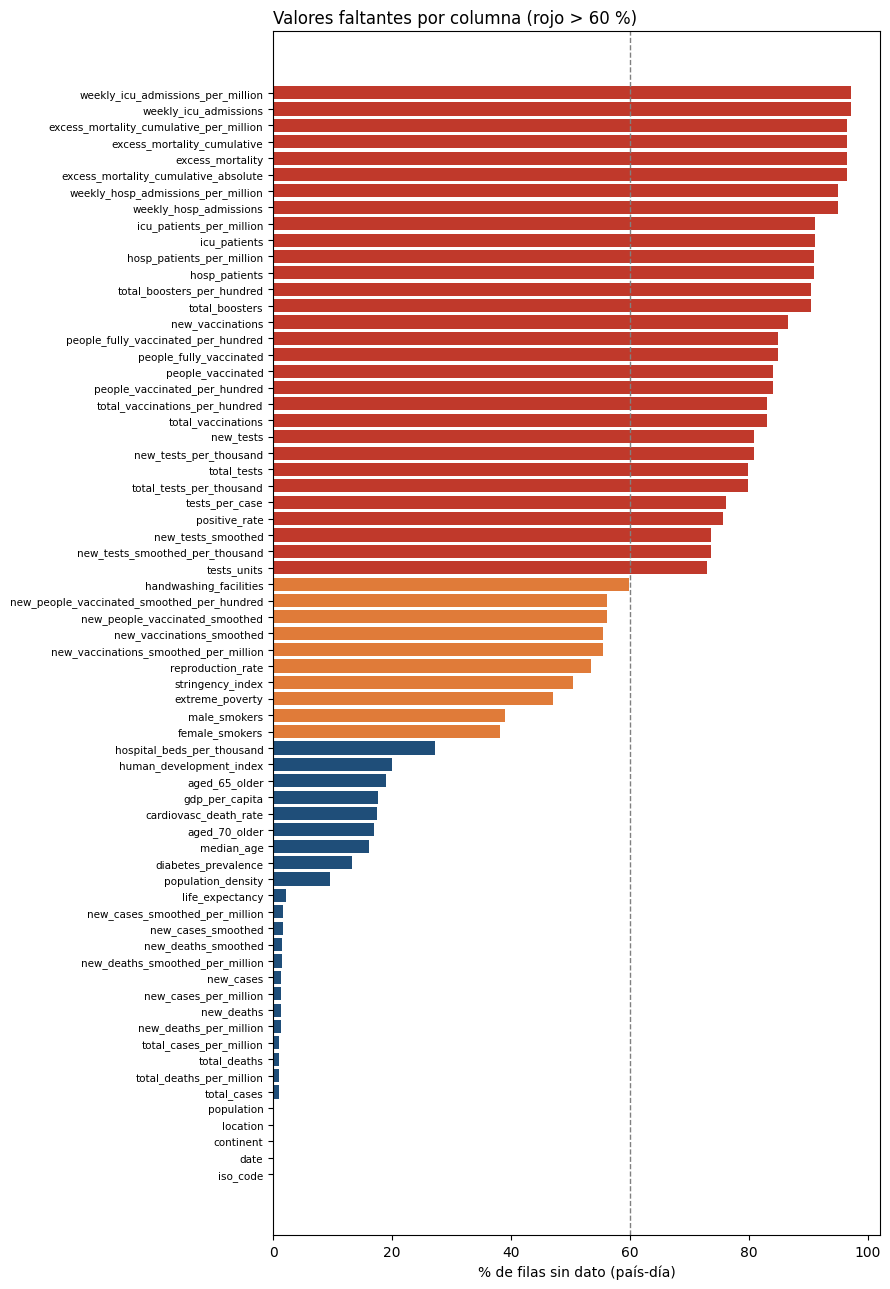

In [29]:
faltantes = (df.isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 13))
colores = ["#c0392b" if v > 60 else "#e07b39" if v > 30 else "#1f4e79" for v in faltantes.values]
ax.barh(faltantes.index, faltantes.values, color=colores)
ax.axvline(60, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("% de filas sin dato (país-día)")
ax.set_title("Valores faltantes por columna (rojo > 60 %)", loc="left")
ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout()
plt.show()

In [30]:
FLUJOS = ["new_cases", "new_deaths"]                              # se suman dentro de la semana
ACUMULADOS = ["total_cases", "total_deaths", "total_vaccinations", "people_vaccinated",
              "people_fully_vaccinated", "total_boosters", "excess_mortality_cumulative_per_million"]
PROMEDIOS = ["stringency_index"]
FIJAS = ["population", "gdp_per_capita", "median_age", "aged_65_older", "life_expectancy",
         "human_development_index", "hospital_beds_per_thousand", "extreme_poverty"]

df = df[["iso_code", "location", "continent", "date"] + FLUJOS + ACUMULADOS + PROMEDIOS + FIJAS]
print("Columnas conservadas:", df.shape[1], "de", raw.shape[1])

Columnas conservadas: 22 de 67


## 4. Transformación

In [31]:
df["semana"] = df["date"].dt.to_period("W-SUN").dt.end_time.dt.normalize()   # domingo de esa semana

reglas = {**{c: lambda s: s.sum(min_count=1) for c in FLUJOS},     # min_count=1: si toda la semana está vacía, queda vacío
          **{c: "last" for c in ACUMULADOS},                       # 'last' = último valor NO vacío de la semana
          **{c: "mean" for c in PROMEDIOS}}

sem = (df.sort_values("date")
         .groupby(["iso_code", "semana"], as_index=False)
         .agg(reglas))
print("Filas país-día:", len(df), "-> filas país-semana:", len(sem))
sem.head()

Filas país-día: 395577 -> filas país-semana: 56717


,iso_code,semana,new_cases,new_deaths,total_cases,total_deaths,total_vaccinations,people_vaccinated,people_fully_vaccinated,total_boosters,excess_mortality_cumulative_per_million,stringency_index
0,ABW,2020-01-05,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0
1,ABW,2020-01-12,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0
2,ABW,2020-01-19,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0
3,ABW,2020-01-26,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0
4,ABW,2020-02-02,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,106.01,0.0


In [32]:
VACUNAS = ["total_vaccinations", "people_vaccinated", "people_fully_vaccinated", "total_boosters"]
nulos_antes = sem[VACUNAS].isna().sum()

sem = sem.sort_values(["iso_code", "semana"])
# Semana en que cada país aplicó su primera dosis (según el total de dosis)
inicio = sem[sem["total_vaccinations"] > 0].groupby("iso_code")["semana"].min()
antes_de_vacunar = sem["semana"] < sem["iso_code"].map(inicio)

for col in VACUNAS:
    arrastre = sem.groupby("iso_code")[col].ffill()                  # arrastra el último valor reportado
    ya_reporto = sem.groupby("iso_code")[col].transform(lambda s: s.notna().cumsum() > 0)
    # Si ya reportó: último valor. Si aún no había vacunación en el país: 0. Si no, vacío (no se inventa).
    sem[col] = np.where(ya_reporto, arrastre, np.where(antes_de_vacunar, 0, np.nan))

pd.DataFrame({"vacíos antes": nulos_antes, "vacíos después": sem[VACUNAS].isna().sum()})

,vacíos antes,vacíos después
total_vaccinations,39063,4561
people_vaccinated,39914,4652
people_fully_vaccinated,40796,6220
total_boosters,47279,16292


In [33]:
pob = df.groupby("iso_code")["population"].first()
sem["poblacion"] = sem["iso_code"].map(pob)

sem["muertes_por_millon_acum"] = sem["total_deaths"] / sem["poblacion"] * 1e6
sem["casos_por_millon_acum"]   = sem["total_cases"] / sem["poblacion"] * 1e6
sem["muertes_semana_por_millon"] = sem["new_deaths"] / sem["poblacion"] * 1e6
sem["pct_vacunados"]       = sem["people_vaccinated"] / sem["poblacion"] * 100
sem["pct_esquema_completo"] = sem["people_fully_vaccinated"] / sem["poblacion"] * 100

print("Semanas con % de vacunados > 100 %:", int((sem["pct_vacunados"] > 100).sum()),
      "en", sem.loc[sem["pct_vacunados"] > 100, "iso_code"].nunique(), "países")
sem.loc[sem["pct_vacunados"] > 100].groupby("iso_code")["pct_vacunados"].max().sort_values(ascending=False).head()

Semanas con % de vacunados > 100 %: 697 en 6 países


iso_code
GIB    129.066316
TKL    116.376123
QAT    105.827064
ARE    105.825050
NRU    103.270034
Name: pct_vacunados, dtype: float64

## 5. Dimensiones

In [35]:
# Verificación: ¿alguna variable "fija" cambia de valor dentro de un mismo país?
cambian = (df.groupby("iso_code")[FIJAS].nunique() > 1).sum()
print("Países donde la variable cambia en el tiempo:")
print(cambian)

Países donde la variable cambia en el tiempo:
population                    0
gdp_per_capita                0
median_age                    0
aged_65_older                 0
life_expectancy               0
human_development_index       0
hospital_beds_per_thousand    0
extreme_poverty               0
dtype: int64


In [36]:
CONTINENTE_ES = {"Africa": "África", "Asia": "Asia", "Europe": "Europa", "North America": "América del Norte",
                 "South America": "América del Sur", "Oceania": "Oceanía"}

# ---- dim_continente
dim_continente = (pd.DataFrame({"continente": sorted(CONTINENTE_ES.values())})
                  .assign(id_continente=lambda d: range(1, len(d) + 1)))

# ---- dim_pais
dim_pais = (df.groupby("iso_code")
              .agg(pais=("location", "first"), continente_en=("continent", "first"),
                   **{c: (c, "first") for c in FIJAS})
              .reset_index()
              .rename(columns={"population": "poblacion", "gdp_per_capita": "pib_per_capita",
                               "median_age": "edad_mediana", "aged_65_older": "pct_65_o_mas",
                               "life_expectancy": "esperanza_vida", "human_development_index": "idh",
                               "hospital_beds_per_thousand": "camas_por_mil", "extreme_poverty": "pct_pobreza_extrema"}))
dim_pais["continente"] = dim_pais["continente_en"].map(CONTINENTE_ES)
dim_pais = dim_pais.drop(columns="continente_en").merge(dim_continente, on="continente")

# Grupo de PIB por cuartiles: permite segmentar H1 en el dashboard
dim_pais["grupo_pib"] = pd.qcut(dim_pais["pib_per_capita"], 4,
                                labels=["1. Bajo", "2. Medio-bajo", "3. Medio-alto", "4. Alto"])
dim_pais["grupo_pib"] = dim_pais["grupo_pib"].cat.add_categories("Sin dato").fillna("Sin dato")

print("Países:", len(dim_pais), "| sin PIB per cápita:", int(dim_pais["pib_per_capita"].isna().sum()))
print(dim_pais.groupby("grupo_pib", observed=True)["pib_per_capita"].agg(["count", "min", "max"]).round(0))
dim_pais.head()

Países: 238 | sin PIB per cápita: 43
               count      min       max
grupo_pib                              
1. Bajo           49    661.0    3823.0
2. Medio-bajo     49   4228.0   12295.0
3. Medio-alto     48  12896.0   27216.0
4. Alto           49  27718.0  116936.0
Sin dato           0      NaN       NaN


,iso_code,pais,poblacion,pib_per_capita,edad_mediana,pct_65_o_mas,esperanza_vida,idh,camas_por_mil,pct_pobreza_extrema,continente,id_continente,grupo_pib
0,ABW,Aruba,106459,35973.78,41.2,13.08,76.29,NaN,NaN,NaN,América del Norte,1,4. Alto
1,AFG,Afghanistan,41128772,1803.99,18.6,2.58,64.83,0.51,0.50,NaN,Asia,3,1. Bajo
2,AGO,Angola,35588996,5819.50,16.8,2.40,61.15,0.58,NaN,NaN,África,6,2. Medio-bajo
3,AIA,Anguilla,15877,NaN,NaN,NaN,81.88,NaN,NaN,NaN,América del Norte,1,Sin dato
4,ALB,Albania,2842318,11803.43,38.0,13.19,78.57,0.80,2.89,1.1,Europa,4,2. Medio-bajo


43 países y territorios no tienen PIB per cápita en OWID (por ejemplo, Taiwán, Siria o varias islas pequeñas). **No se imputan**: inventar un PIB alteraría directamente el resultado de H1. Quedan en el grupo «Sin dato» y se excluyen solo de los análisis que usan el PIB.

In [37]:
# ---- dim_fecha (una fila por semana)
MESES = {1: "Enero", 2: "Febrero", 3: "Marzo", 4: "Abril", 5: "Mayo", 6: "Junio", 7: "Julio",
         8: "Agosto", 9: "Septiembre", 10: "Octubre", 11: "Noviembre", 12: "Diciembre"}
dim_fecha = pd.DataFrame({"semana": pd.date_range(sem["semana"].min(), sem["semana"].max(), freq="W-SUN")})
dim_fecha["anio"] = dim_fecha["semana"].dt.year
dim_fecha["trimestre"] = "T" + dim_fecha["semana"].dt.quarter.astype(str)
dim_fecha["num_mes"] = dim_fecha["semana"].dt.month                 # sirve para ordenar los meses en Power BI
dim_fecha["mes"] = dim_fecha["num_mes"].map(MESES)
dim_fecha["semana_iso"] = dim_fecha["semana"].dt.isocalendar().week.astype(int)
# Etapa de la pandemia: separa el periodo sin vacunas del periodo de vacunación (útil para H2)
dim_fecha["etapa"] = np.select(
    [dim_fecha["semana"] < "2020-12-13", dim_fecha["semana"] < "2022-01-01"],
    ["1. Antes de vacunas", "2. Vacunación masiva (2021)"], "3. Después de 2021")
print("Semanas:", len(dim_fecha), "|", dim_fecha["semana"].min().date(), "->", dim_fecha["semana"].max().date())
dim_fecha.groupby("etapa").size()

Semanas: 242 | 2020-01-05 -> 2024-08-18


etapa
1. Antes de vacunas             49
2. Vacunación masiva (2021)     55
3. Después de 2021             138
dtype: int64

## 6. Tabla de hechos y validación

In [38]:
fact = sem.rename(columns={
    "new_cases": "casos_nuevos", "new_deaths": "muertes_nuevas",
    "total_cases": "casos_acum", "total_deaths": "muertes_acum",
    "total_vaccinations": "dosis_aplicadas_acum", "people_vaccinated": "personas_vacunadas_acum",
    "people_fully_vaccinated": "personas_esquema_completo_acum", "total_boosters": "refuerzos_acum",
    "excess_mortality_cumulative_per_million": "exceso_mortalidad_acum_por_millon",
    "stringency_index": "indice_restricciones"})

fact = fact[["semana", "iso_code", "casos_nuevos", "muertes_nuevas", "casos_acum", "muertes_acum",
             "dosis_aplicadas_acum", "personas_vacunadas_acum", "personas_esquema_completo_acum", "refuerzos_acum",
             "muertes_semana_por_millon", "muertes_por_millon_acum", "casos_por_millon_acum",
             "pct_vacunados", "pct_esquema_completo", "vacunacion_ajustada_100",
             "exceso_mortalidad_acum_por_millon", "indice_restricciones"]]
print("Tabla de hechos:", fact.shape)
fact[fact["iso_code"] == "COL"].iloc[60:65]

Tabla de hechos: (56717, 18)


,semana,iso_code,casos_nuevos,muertes_nuevas,casos_acum,muertes_acum,dosis_aplicadas_acum,personas_vacunadas_acum,personas_esquema_completo_acum,refuerzos_acum,muertes_semana_por_millon,muertes_por_millon_acum,casos_por_millon_acum,pct_vacunados,pct_esquema_completo,vacunacion_ajustada_100,exceso_mortalidad_acum_por_millon,indice_restricciones
10620,2021-02-28,COL,27791.0,1007.0,2244792.0,59518.0,130578.0,NaN,NaN,NaN,19.412412,1147.356438,43273.909634,NaN,NaN,False,1441.77,81.02
10621,2021-03-07,COL,24790.0,782.0,2269582.0,60300.0,299400.0,NaN,NaN,NaN,15.074981,1162.431419,43751.798106,NaN,NaN,False,1459.55,81.02
10622,2021-03-14,COL,25035.0,650.0,2294617.0,60950.0,843204.0,803656.0,39548.0,NaN,12.530355,1174.961775,44234.409558,1.549245,0.076239,False,1471.57,81.02
10623,2021-03-21,COL,29809.0,821.0,2324426.0,61771.0,1215008.0,1157159.0,57849.0,NaN,15.826803,1190.788577,44809.051651,2.230710,0.111518,False,1488.41,81.02
10624,2021-03-28,COL,42911.0,874.0,2367337.0,62645.0,1818861.0,1624565.0,194296.0,NaN,16.848508,1207.637086,45636.267151,3.131750,0.374554,False,1513.32,81.02


In [ ]:
mundo = raw[raw["location"] == "World"].assign(date=lambda d: pd.to_datetime(d["date"]))
mundo_final = mundo[mundo["date"] == ultima_fecha_con_datos].iloc[0]
ultima_semana = fact[fact["semana"] == fact["semana"].max()]

print(f"Muertes  · suma de países: {ultima_semana['muertes_acum'].sum():>14,.0f} | World: {mundo_final['total_deaths']:>14,.0f}")
print(f"Casos    · suma de países: {ultima_semana['casos_acum'].sum():>14,.0f} | World: {mundo_final['total_cases']:>14,.0f}")

"""assert ultima_semana["muertes_acum"].sum() == mundo_final["total_deaths"], "No cuadra el total de muertes"
assert ultima_semana["casos_acum"].sum() == mundo_final["total_cases"], "No cuadra el total de casos"
assert not fact.duplicated(["semana", "iso_code"]).any(), "Hay país-semana duplicado"
assert fact["iso_code"].isin(dim_pais["iso_code"]).all(), "Hay países en hechos sin dimensión"
print("\nValidación OK: los totales cuadran exactamente con World")"""

Muertes  · suma de países:              0 | World:      7,057,132
Casos    · suma de países:              0 | World:    775,866,783


AssertionError: No cuadra el total de muertes